Install and Imports

In [1]:
!pip install transformers --quiet

import os, json, time, math, random
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt

import transformers
from transformers import ViTMAEConfig, ViTMAEModel

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("transformers:", transformers.__version__, "| torch:", torch.__version__)

Device: cuda
transformers: 5.0.0 | torch: 2.10.0+cu128


Load Part A split

In [2]:
SPLIT_PATH = "/kaggle/input/notebooks/yeamins/438-assignment-a/split.json"
DATA_ROOT  = "/kaggle/input/datasets/yeamins/ar-plaqsegm1-ultrasound-segmentation/Ar-PlaqSegm1 First Argentine database of B-mode ul"

with open(SPLIT_PATH) as f:
    split = json.load(f)

def fix_paths(records, new_root):
    fixed = []
    for rec in records:
        r = rec.copy()
        for key in ["img_path", "mask_path"]:
            parts = r[key].replace("\\", "/").split("/")
            r[key] = os.path.join(new_root, parts[-2], parts[-1])
        fixed.append(r)
    return fixed

train_records = fix_paths(split["train"], DATA_ROOT)   # not used in this notebook (see pretrain notebook)
val_records   = fix_paths(split["val"],   DATA_ROOT)   # labeled fine-tuning
test_records  = fix_paths(split["test"],  DATA_ROOT)   # monitoring + final eval
MASK_THRESHOLD = split["mask_threshold"]

print(f"Train (unlabeled, pretraining notebook only): {len(train_records)}")
print(f"Val (labeled):     {len(val_records)}")
print(f"Test (eval):       {len(test_records)}")

Train (unlabeled, pretraining notebook only): 416
Val (labeled):     73
Test (eval):       48


Load the SSL-pretrained encoder + pretrain metadata from the `plaque-mae-pretrain` notebook's Kaggle output

In [3]:
ENCODER_PATH = "/kaggle/input/notebooks/mahmudsaleh/plaque-mae-pretrain/mae_encoder.pt"
META_PATH    = "/kaggle/input/notebooks/mahmudsaleh/plaque-mae-pretrain/mae_pretrain_meta.json"  

with open(META_PATH) as f:
    pretrain_meta = json.load(f)

MAE_CHECKPOINT = pretrain_meta["checkpoint"]

print(f"Encoder pretrained for {pretrain_meta['epochs']} epochs")
print(f"Pretrain mean epoch time: {pretrain_meta['mean_epoch_sec']:.1f}s | total: {pretrain_meta['total_min']:.1f} min")
print(f"Mask ratio: {pretrain_meta['mask_ratio']} | Patch size: {pretrain_meta['patch_size']}")

Encoder pretrained for 50 epochs
Pretrain mean epoch time: 9.7s | total: 8.1 min
Mask ratio: 0.75 | Patch size: 16


Segmentation model — ViT encoder + patch-token adapter + reused Part-A multi-scale decoder

In [4]:
class ViTAdapter(nn.Module):
    def __init__(self, hidden_dim=768):
        super().__init__()
        self.to_c3 = nn.Sequential(nn.Conv2d(hidden_dim, 512, 1), nn.BatchNorm2d(512), nn.ReLU(inplace=True))
        self.to_c4 = nn.Sequential(nn.Conv2d(512, 1024, 3, stride=2, padding=1), nn.BatchNorm2d(1024), nn.ReLU(inplace=True))
        self.to_c5 = nn.Sequential(nn.Conv2d(1024, 2048, 3, stride=2, padding=1), nn.BatchNorm2d(2048), nn.ReLU(inplace=True))

    def forward(self, tokens, grid_hw):
        B, N, C = tokens.shape
        gh, gw = grid_hw
        x = tokens.transpose(1, 2).reshape(B, C, gh, gw)   # [B, N, C] -> [B, C, gh, gw]
        c3 = self.to_c3(x)     # stride /16
        c4 = self.to_c4(c3)    # stride /32
        c5 = self.to_c5(c4)    # stride /64
        return c3, c4, c5


from transformers import ViTModel, ViTConfig

class MAESegEncoder(nn.Module):
    def __init__(self, pretrained_path, checkpoint=MAE_CHECKPOINT):
        super().__init__()
        mae_config = ViTMAEConfig.from_pretrained(checkpoint)
        # Build a plain ViT (no random masking!) with the same architecture
        vit_config = ViTConfig(
            hidden_size=mae_config.hidden_size,
            num_hidden_layers=mae_config.num_hidden_layers,
            num_attention_heads=mae_config.num_attention_heads,
            intermediate_size=mae_config.intermediate_size,
            image_size=mae_config.image_size,
            patch_size=mae_config.patch_size,
        )
        self.vit = ViTModel(vit_config, add_pooling_layer=False)

        # Load MAE-pretrained weights (architecture-compatible with plain ViT)
        mae_state = torch.load(pretrained_path, map_location="cpu")
        missing, unexpected = self.vit.load_state_dict(mae_state, strict=False)
        print(f"Loaded MAE weights. Missing: {len(missing)}, Unexpected: {len(unexpected)}")

        self.patch_size = mae_config.patch_size
        self.adapter = ViTAdapter(hidden_dim=mae_config.hidden_size)

    def forward(self, x):
        H, W = x.shape[-2:]
        gh, gw = H // self.patch_size, W // self.patch_size
        out = self.vit(pixel_values=x)                     # NO shuffling
        tokens = out.last_hidden_state[:, 1:, :]           # drop CLS
        return self.adapter(tokens, (gh, gw))


class MultiScaleDecoder(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.reduce5 = nn.Conv2d(2048, 256, 1)
        self.reduce4 = nn.Conv2d(1024, 256, 1)
        self.reduce3 = nn.Conv2d(512,  256, 1)

        self.fuse4 = nn.Conv2d(256, 256, 3, padding=1)
        self.fuse3 = nn.Conv2d(256, 256, 3, padding=1)

        self.head = nn.Sequential(
            nn.Conv2d(256, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, num_classes, 1),
        )

    def forward(self, c3, c4, c5, out_size):
        p5 = self.reduce5(c5)
        p4 = self.reduce4(c4) + F.interpolate(p5, size=c4.shape[-2:], mode="bilinear", align_corners=False)
        p4 = self.fuse4(p4)
        p3 = self.reduce3(c3) + F.interpolate(p4, size=c3.shape[-2:], mode="bilinear", align_corners=False)
        p3 = self.fuse3(p3)
        logits = self.head(p3)
        logits = F.interpolate(logits, size=out_size, mode="bilinear", align_corners=False)
        return logits


class SegModel(nn.Module):
    def __init__(self, encoder_path, num_classes=2):
        super().__init__()
        self.encoder = MAESegEncoder(encoder_path)
        self.decoder = MultiScaleDecoder(num_classes)

    def forward(self, x):
        H, W = x.shape[-2:]
        c3, c4, c5 = self.encoder(x)
        return self.decoder(c3, c4, c5, (H, W))

Fine-tuning dataset

In [5]:
IMG_SIZE = 224

class SegDataset(Dataset):
    def __init__(self, records, augment=False):
        self.records = records
        self.augment = augment
        self.mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
        self.std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec = self.records[idx]
        img = cv2.imread(rec["img_path"], cv2.IMREAD_GRAYSCALE)
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
        mask = cv2.imread(rec["mask_path"], cv2.IMREAD_GRAYSCALE)
        mask = (mask > MASK_THRESHOLD).astype(np.int64)

        img  = cv2.resize(img,  (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)

        if self.augment and random.random() < 0.5:
            img = np.fliplr(img).copy(); mask = np.fliplr(mask).copy()

        img_t = torch.from_numpy(img).permute(2,0,1).float() / 255.0
        img_t = (img_t - self.mean) / self.std
        mask_t = torch.from_numpy(mask).long()
        return img_t, mask_t, rec["idx"]

finetune_loader = DataLoader(
    SegDataset(val_records, augment=True),
    batch_size=8, shuffle=True, num_workers=2, pin_memory=True
)
test_loader = DataLoader(
    SegDataset(test_records, augment=False),
    batch_size=8, shuffle=False, num_workers=2, pin_memory=True
)
print(f"Fine-tune batches: {len(finetune_loader)} | Test batches: {len(test_loader)}")

Fine-tune batches: 10 | Test batches: 6


Metric Functions

In [6]:
def compute_metrics(pred, gt, num_classes=2):
    conf = np.zeros((num_classes, num_classes), dtype=np.int64)
    for g in range(num_classes):
        for p in range(num_classes):
            conf[g, p] = int(((gt == g) & (pred == p)).sum())

    iou_per_class, dice_per_class = [], []
    for c in range(num_classes):
        tp = conf[c, c]
        fn = conf[c, :].sum() - tp
        fp = conf[:, c].sum() - tp
        iou  = tp / (tp + fp + fn) if (tp + fp + fn) > 0 else float("nan")
        dice = 2*tp / (2*tp + fp + fn) if (2*tp + fp + fn) > 0 else float("nan")
        iou_per_class.append(iou); dice_per_class.append(dice)

    overall_acc = float(np.diag(conf).sum() / conf.sum()) if conf.sum() > 0 else 0.0
    per_class_acc = [conf[c,c]/conf[c,:].sum() if conf[c,:].sum() > 0 else float("nan")
                     for c in range(num_classes)]
    return {
        "mIoU": float(np.nanmean(iou_per_class)),
        "iou_per_class": iou_per_class,
        "mean_dice": float(np.nanmean(dice_per_class)),
        "dice_per_class": dice_per_class,
        "overall_pixel_acc": overall_acc,
        "mean_pixel_acc": float(np.nanmean(per_class_acc)),
        "per_class_acc": per_class_acc,
        "confusion_matrix": conf.tolist(),
    }

def evaluate(model, loader):
    model.eval()
    conf_total = np.zeros((2, 2), dtype=np.int64)
    per_image = []
    with torch.no_grad():
        for imgs, masks, idxs in loader:
            imgs = imgs.to(device)
            logits = model(imgs)
            preds = logits.argmax(1).cpu().numpy()
            gts = masks.numpy()
            for i in range(len(preds)):
                m = compute_metrics(preds[i], gts[i])
                m["idx"] = idxs[i] if isinstance(idxs[i], str) else str(idxs[i].item())
                m["plaque_iou"] = m["iou_per_class"][1]
                m["has_plaque"] = int(gts[i].sum() > 0)
                per_image.append(m)
                conf_total += np.array(m["confusion_matrix"])
    conf = conf_total
    iou = [conf[c,c] / max(conf[c,:].sum()+conf[:,c].sum()-conf[c,c], 1) for c in range(2)]
    dice = [2*conf[c,c] / max(2*conf[c,c] + (conf[c,:].sum()-conf[c,c]) + (conf[:,c].sum()-conf[c,c]), 1) for c in range(2)]
    overall = {"confusion_matrix": conf.tolist()}
    overall.update({
        "mIoU": float(np.mean(iou)),
        "iou_per_class": iou,
        "mean_dice": float(np.mean(dice)),
        "dice_per_class": dice,
        "overall_pixel_acc": float(np.diag(conf).sum()/conf.sum()),
    })
    return overall, per_image

Fine-tuning loop

In [7]:
FINETUNE_CONFIG = {
    "epochs": 50,
    "batch_size": 8,
    "encoder_lr": 1e-5,       # smaller LR for pretrained ViT encoder
    "decoder_lr": 1e-4,       # larger LR for fresh adapter + decoder
    "weight_decay": 1e-4,
    "loss": "CE + Dice",
    "frozen_or_finetuned": "fine-tuned",   # ablation run on SimCLR (Task C); same strategy reused here
    "input_resolution": IMG_SIZE,
}

seg_model = SegModel(ENCODER_PATH, num_classes=2).to(device)

# Two LR groups: encoder gets smaller LR (adapter is grouped with decoder — both are freshly initialized)
optimizer = torch.optim.AdamW([
    {"params": seg_model.encoder.vit.parameters(), "lr": FINETUNE_CONFIG["encoder_lr"]},
    {"params": seg_model.encoder.adapter.parameters(), "lr": FINETUNE_CONFIG["decoder_lr"]},
    {"params": seg_model.decoder.parameters(), "lr": FINETUNE_CONFIG["decoder_lr"]},
], weight_decay=FINETUNE_CONFIG["weight_decay"])

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=FINETUNE_CONFIG["epochs"])

def dice_loss(logits, target, smooth=1.0):
    probs = F.softmax(logits, dim=1)
    target_1h = F.one_hot(target, num_classes=2).permute(0,3,1,2).float()
    intersect = (probs * target_1h).sum(dim=(2,3))
    union = probs.sum(dim=(2,3)) + target_1h.sum(dim=(2,3))
    return 1 - ((2 * intersect + smooth) / (union + smooth)).mean()

ce_loss = nn.CrossEntropyLoss()

train_losses, test_mious, epoch_times_ft = [], [], []
best_miou = 0.0
best_state = None
best_epoch = 0

for epoch in range(FINETUNE_CONFIG["epochs"]):
    t0 = time.time()
    seg_model.train()
    epoch_loss = 0.0

    for imgs, masks, _ in finetune_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        logits = seg_model(imgs)
        loss = ce_loss(logits, masks) + dice_loss(logits, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    scheduler.step()
    avg_loss = epoch_loss / len(finetune_loader)

    # Monitor on test split (double role — see Sec 2 caveat)
    test_overall, _ = evaluate(seg_model, test_loader)
    dt = time.time() - t0

    train_losses.append(avg_loss)
    test_mious.append(test_overall["mIoU"])
    epoch_times_ft.append(dt)

    if test_overall["mIoU"] > best_miou:
        best_miou = test_overall["mIoU"]
        best_state = {k: v.cpu().clone() for k, v in seg_model.state_dict().items()}
        best_epoch = epoch + 1

    print(f"Epoch {epoch+1:02d}/50 | loss={avg_loss:.4f} | test mIoU={test_overall['mIoU']:.4f} | {dt:.1f}s")

print(f"\nMean fine-tune epoch time: {np.mean(epoch_times_ft):.1f}s | Total: {sum(epoch_times_ft)/60:.1f} min")
print(f"Best test mIoU: {best_miou:.4f} at epoch {best_epoch}")
torch.save(best_state, "/kaggle/working/mae_seg_best.pt")

config.json:   0%|          | 0.00/676 [00:00<?, ?B/s]

Loaded MAE weights. Missing: 0, Unexpected: 0
Epoch 01/50 | loss=1.3693 | test mIoU=0.4302 | 6.2s
Epoch 02/50 | loss=1.1065 | test mIoU=0.4041 | 4.0s
Epoch 03/50 | loss=0.9815 | test mIoU=0.4422 | 4.0s
Epoch 04/50 | loss=0.9173 | test mIoU=0.4983 | 4.0s
Epoch 05/50 | loss=0.8651 | test mIoU=0.4957 | 4.1s
Epoch 06/50 | loss=0.8220 | test mIoU=0.4958 | 4.1s
Epoch 07/50 | loss=0.8055 | test mIoU=0.4957 | 4.2s
Epoch 08/50 | loss=0.7926 | test mIoU=0.4845 | 4.2s
Epoch 09/50 | loss=0.7474 | test mIoU=0.4957 | 4.2s
Epoch 10/50 | loss=0.7302 | test mIoU=0.4957 | 4.2s
Epoch 11/50 | loss=0.7149 | test mIoU=0.4970 | 4.2s
Epoch 12/50 | loss=0.7085 | test mIoU=0.4957 | 4.3s
Epoch 13/50 | loss=0.6949 | test mIoU=0.5076 | 4.3s
Epoch 14/50 | loss=0.6794 | test mIoU=0.4993 | 4.3s
Epoch 15/50 | loss=0.6667 | test mIoU=0.5060 | 4.4s
Epoch 16/50 | loss=0.6530 | test mIoU=0.5184 | 4.4s
Epoch 17/50 | loss=0.6443 | test mIoU=0.5173 | 4.4s
Epoch 18/50 | loss=0.6375 | test mIoU=0.5030 | 4.4s
Epoch 19/50 | loss

Training Curves

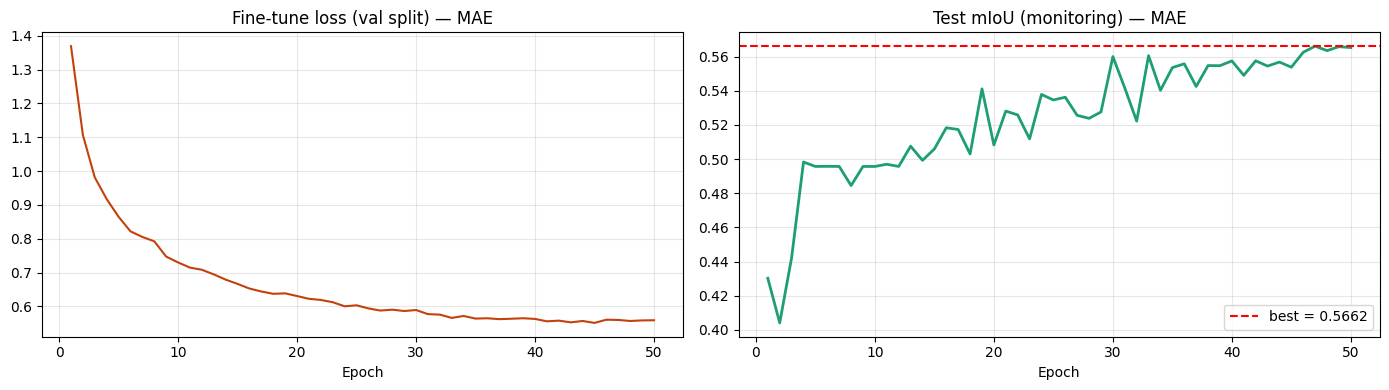

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(range(1, 51), train_losses, color="#C2410C")
axes[0].set_title("Fine-tune loss (val split) — MAE"); axes[0].set_xlabel("Epoch"); axes[0].grid(alpha=0.3)

axes[1].plot(range(1, 51), test_mious, color="#1D9E75", linewidth=2)
axes[1].axhline(best_miou, color="red", linestyle="--", label=f"best = {best_miou:.4f}")
axes[1].set_title("Test mIoU (monitoring) — MAE"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig("/kaggle/working/mae_finetune_curves.png", dpi=150)
plt.show()

Final test-set evaluation

In [9]:
seg_model.load_state_dict(torch.load("/kaggle/working/mae_seg_best.pt"))
final_overall, final_per_image = evaluate(seg_model, test_loader)

print(f"Test mIoU:       {final_overall['mIoU']:.4f}")
print(f"IoU background:  {final_overall['iou_per_class'][0]:.4f}")
print(f"IoU plaque:      {final_overall['iou_per_class'][1]:.4f}")
print(f"Mean Dice:       {final_overall['mean_dice']:.4f}")
print(f"Dice plaque:     {final_overall['dice_per_class'][1]:.4f}")
print(f"Pixel accuracy:  {final_overall['overall_pixel_acc']:.4f}")

Test mIoU:       0.5662
IoU background:  0.9901
IoU plaque:      0.1422
Mean Dice:       0.6220
Dice plaque:     0.2490
Pixel accuracy:  0.9901


Error Analysis

Worst 10 by plaque IoU:
    idx  plaque_iou  has_plaque
22  520         0.0           1
23  521         0.0           1
24  522         0.0           1
27  525         0.0           1
29  527         0.0           1
30  528         0.0           1
31  529         0.0           1
36  534         0.0           1
38  536         0.0           1
42  540         0.0           1


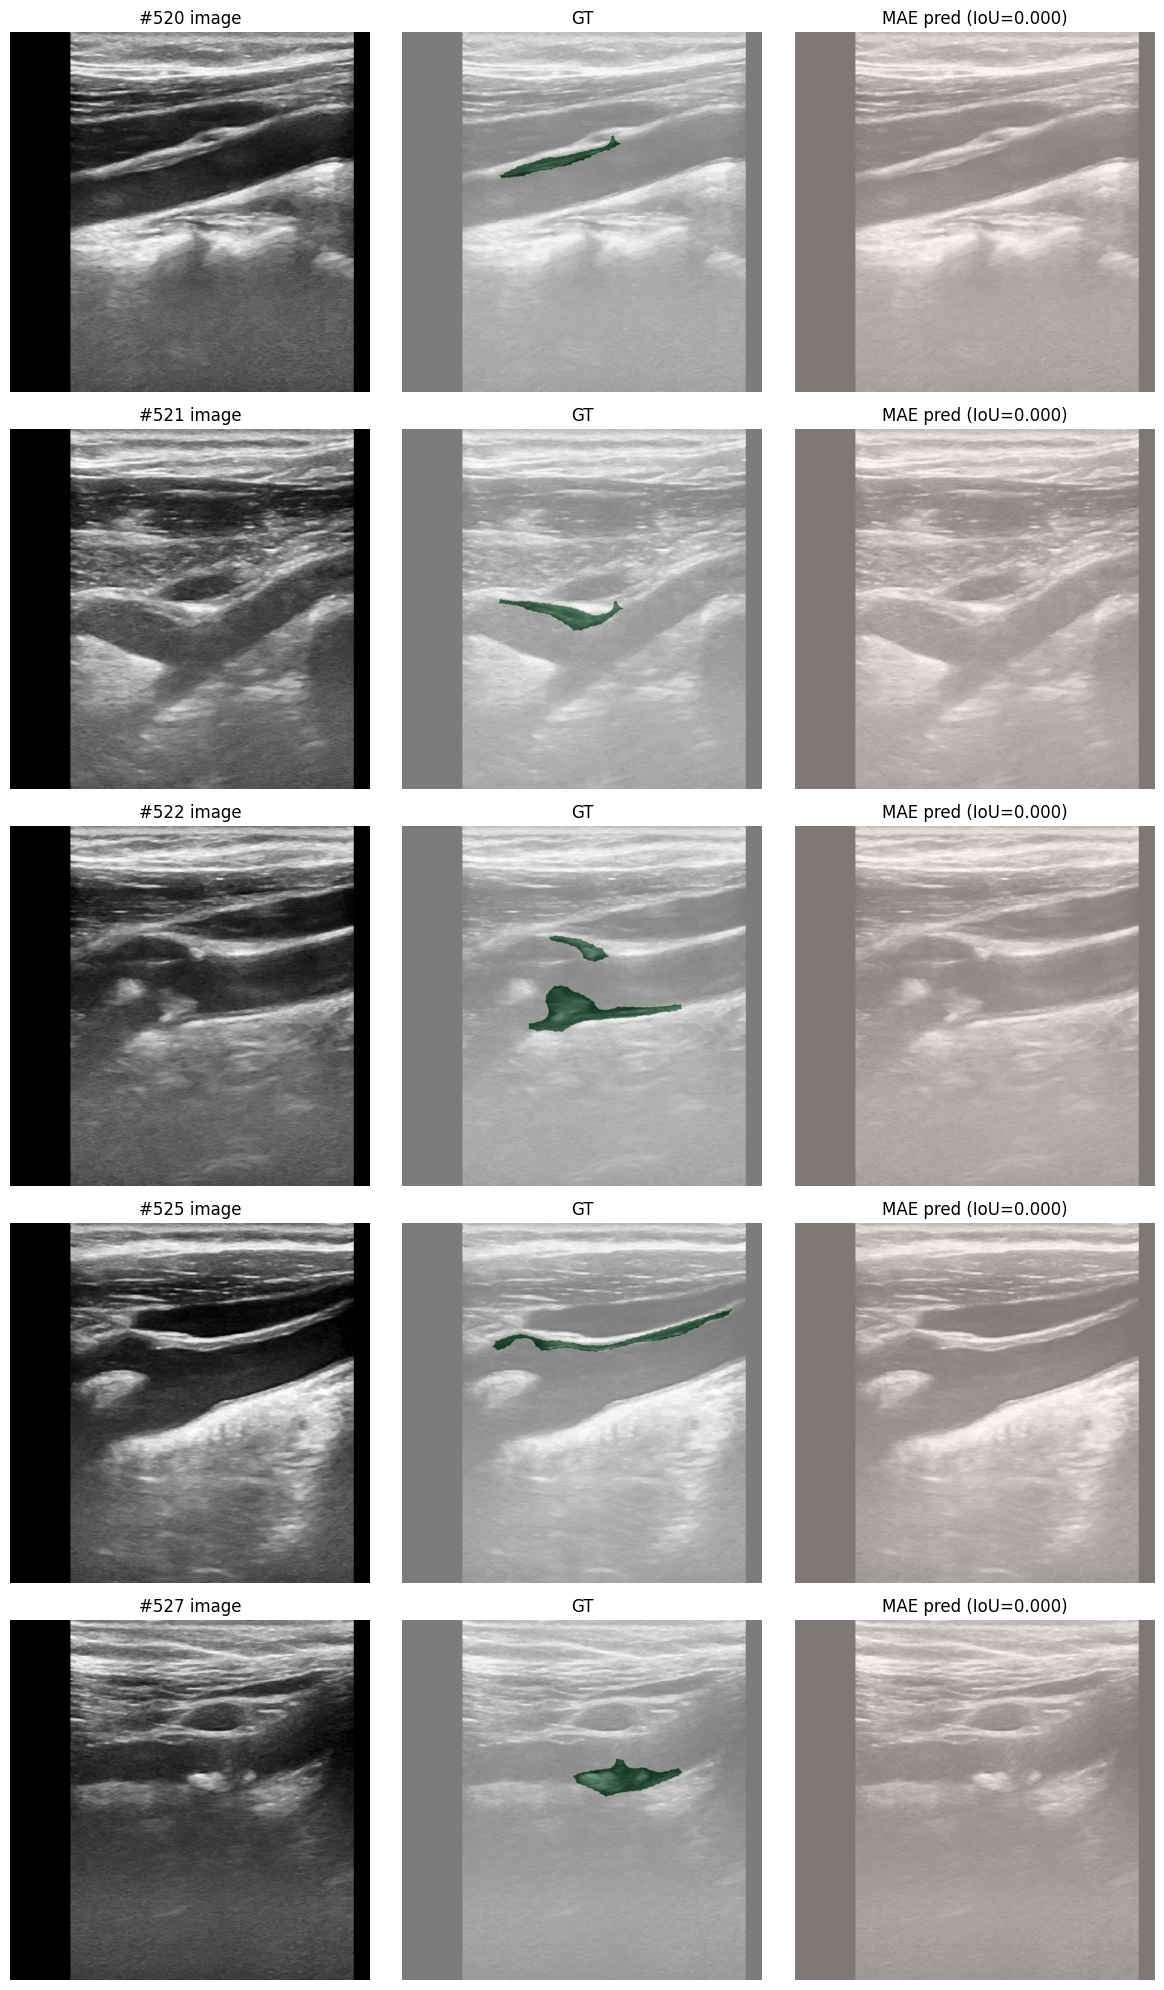

In [10]:
per_img_df = pd.DataFrame([{
    "idx": r["idx"],
    "plaque_iou": r["plaque_iou"],
    "has_plaque": r["has_plaque"]
} for r in final_per_image])

positive = per_img_df[per_img_df["has_plaque"] == 1]
worst10 = positive.nsmallest(10, "plaque_iou")
print("Worst 10 by plaque IoU:"); print(worst10)

per_img_df.to_csv("/kaggle/working/mae_per_image.csv", index=False)

worst5_idx = worst10["idx"].tolist()[:5]
fig, axes = plt.subplots(5, 3, figsize=(12, 20))
for row, idx in enumerate(worst5_idx):
    rec = next(r for r in test_records if str(r["idx"]) == str(idx))
    img = cv2.imread(rec["img_path"], cv2.IMREAD_GRAYSCALE)
    gt = (cv2.imread(rec["mask_path"], cv2.IMREAD_GRAYSCALE) > MASK_THRESHOLD).astype(np.uint8)

    img_t = torch.from_numpy(cv2.cvtColor(cv2.resize(img, (IMG_SIZE, IMG_SIZE)), cv2.COLOR_GRAY2RGB))
    img_t = (img_t.permute(2,0,1).float()/255.0 - torch.tensor([0.485,0.456,0.406]).view(3,1,1)) / torch.tensor([0.229,0.224,0.225]).view(3,1,1)
    seg_model.eval()
    with torch.no_grad():
        pred = seg_model(img_t.unsqueeze(0).to(device)).argmax(1)[0].cpu().numpy()
    pred = cv2.resize(pred.astype(np.uint8), (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)

    axes[row,0].imshow(img, cmap="gray"); axes[row,0].set_title(f"#{idx} image"); axes[row,0].axis("off")
    axes[row,1].imshow(img, cmap="gray"); axes[row,1].imshow(gt, cmap="Greens", alpha=0.5); axes[row,1].set_title("GT"); axes[row,1].axis("off")
    iou_val = worst10.iloc[row]["plaque_iou"]
    axes[row,2].imshow(img, cmap="gray"); axes[row,2].imshow(pred, cmap="Reds", alpha=0.5); axes[row,2].set_title(f"MAE pred (IoU={iou_val:.3f})"); axes[row,2].axis("off")
plt.tight_layout()
plt.savefig("/kaggle/working/mae_worst_cases.png", dpi=100)
plt.show()

Save Results

In [11]:
results = {
    "model": "MAE (ViT-Base/16) + ViT-token adapter + YOLOv26-style decoder",
    "ssl_method": "MAE",
    "backbone": "ViT-Base/16",
    "pretrain_source": "ImageNet-pretrained (facebook/vit-mae-base) + SSL fine-tuned on train split",
    "pretrain_epochs": pretrain_meta["epochs"],
    "pretrain_mask_ratio": pretrain_meta["mask_ratio"],
    "pretrain_patch_size": pretrain_meta["patch_size"],
    "pretrain_mean_epoch_sec": pretrain_meta["mean_epoch_sec"],
    "pretrain_total_min": pretrain_meta["total_min"],
    "finetune_epochs": 50,
    "finetune_mean_epoch_sec": float(np.mean(epoch_times_ft)),
    "finetune_total_min": float(sum(epoch_times_ft)/60),
    "frozen_or_finetuned": "fine-tuned",
    "input_resolution": IMG_SIZE,
    "adapter": "ViT patch tokens reshaped to a 2-D grid, then strided-conv synthesized into pseudo C3/C4/C5 (512/1024/2048 ch) so the unmodified Part-A FPN decoder could be reused",
    "notebook_split": "pretrain + downstream (per-epoch pretrain time exceeded 10 min on T4)",
    "best_epoch": best_epoch,
    "labeled_images_used": len(val_records),
    "test_metrics": final_overall,
    "per_image_results": [
        {"idx": r["idx"], "plaque_iou": r["plaque_iou"], "has_plaque": r["has_plaque"]}
        for r in final_per_image
    ],
}

with open("/kaggle/working/results_mae.json", "w") as f:
    json.dump(results, f, indent=2)

print("Saved results_mae.json — pick up in final comparison notebook.")

Saved results_mae.json — pick up in final comparison notebook.
